In [2]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl.metadata (11 kB)
Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl (8.9 MB)

   ---------- ----------------------------- 1/4 [cloudpickle]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- -------


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import datetime as dt

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load dataset (adjust path or filename if needed)
df = pd.read_csv('../DataAnalytics-L1-EDARetailSales/retail_sales_dataset.csv')

# Clean columns and drop null CustomerIDs
df.columns = df.columns.str.strip()
df = df.dropna(subset=['CustomerID'])
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Compute TotalAmount
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [4]:
# Reference date for recency calculation (one day after the latest invoice in data)
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

# Aggregate RFM values per customer
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
}).reset_index()

# Rename columns
rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']
rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,4344.000000,4344.000000,4344.000000,4344.000000
mean,15299.816989,92.523941,4.594843,2455.498284
std,1722.095010,99.915319,8.301604,9582.990480
min,12346.000000,1.000000,1.000000,3.750000
25%,13811.750000,18.000000,1.000000,311.680000
50%,15299.500000,51.000000,2.000000,712.840000
75%,16779.250000,143.000000,5.000000,1971.450000
max,18287.000000,374.000000,224.000000,282777.640000


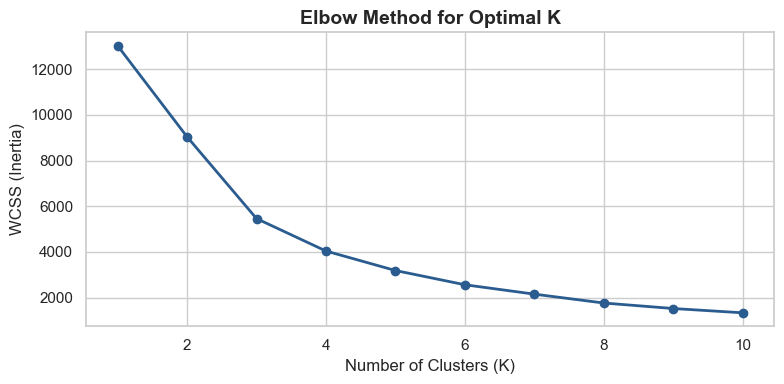

In [5]:
# Standardize features using StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])

# Elbow Method to determine optimal K
wcss = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, marker='o', color='#2b5c8f', linewidth=2)
plt.title('Elbow Method for Optimal K', fontsize=14, weight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('WCSS (Inertia)', fontsize=12)
plt.tight_layout()
plt.show()

In [6]:
# Apply KMeans with K=3 (or K=4 based on the elbow curve)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Average metrics per cluster
cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

print("Cluster Summary Profiles:")
print(cluster_profile)

Cluster Summary Profiles:
        Recency Frequency  Monetary      
           mean      mean      mean count
Cluster                                  
0         41.24      5.06   2351.83  3229
1        245.99      1.71    769.54  1092
2          6.17     76.17  97056.21    23


C:\Users\nikit\AppData\Local\Temp\ipykernel_23200\4254627081.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, x='Cluster', palette='Set1', ax=axes[1])


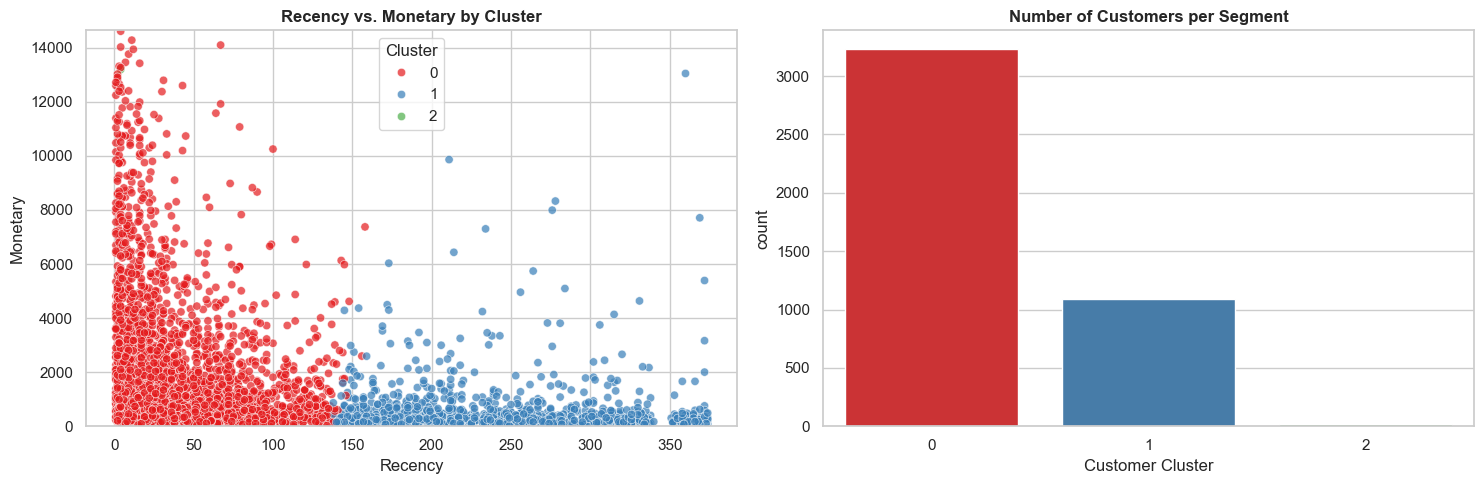

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Scatter: Recency vs Monetary
sns.scatterplot(
    data=rfm, x='Recency', y='Monetary', hue='Cluster',
    palette='Set1', ax=axes[0], alpha=0.7
)
axes[0].set_title('Recency vs. Monetary by Cluster', weight='bold')
axes[0].set_ylim(0, rfm['Monetary'].quantile(0.98))  # clip extreme outliers for clean visual

# Count of customers per cluster
sns.countplot(data=rfm, x='Cluster', palette='Set1', ax=axes[1])
axes[1].set_title('Number of Customers per Segment', weight='bold')
axes[1].set_xlabel('Customer Cluster')

plt.tight_layout()
plt.show()

### Customer Segment Insights & Business Profiles

* **Cluster 0: High-Value Loyalists (Champions)**
  * **Behavior**: Low Recency (purchased very recently), high Frequency, and high Monetary spend.
  * **Strategy**: Offer premium loyalty programs, early access to new product releases, and personalized appreciation perks to maximize retention.

* **Cluster 1: Occasional / Moderate Shoppers**
  * **Behavior**: Moderate Recency and Frequency with average basket value.
  * **Strategy**: Provide personalized product recommendations, bundle discounts, and volume-based offers to increase order size.

* **Cluster 2: At-Risk / Inactive Customers**
  * **Behavior**: High Recency (haven't purchased in a long time) with low Frequency and low spend.
  * **Strategy**: Target with automated win-back email campaigns, feedback surveys, and limited-time re-engagement discounts.